In [ ]:
# imports
import glob
import re
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
# importing data
base_dir = Path("./ATP_reactions")

# Outer dict: {folder_name: {stats_key: dataframe}}
all_data = {}

# iterate through subfolders
for folder in base_dir.iterdir():
    if folder.is_dir():
        folder_name = folder.name
        stats_dict = {}

        # expected stats1..stats10
        for i in range(1, 11):
            key = f"stats{i}"
            file_path = folder / f"{key}.csv"
            if file_path.exists():
                stats_dict[key] = pd.read_csv(file_path)

        all_data[folder_name] = stats_dict

all_data.keys()  # quick look at loaded folders

In [ ]:
# calculate mean and standard deviation
results_mean = {}
results_std  = {}

cols = ['ATP', 'GroEL', 'GroEL_ES_ADP_Na', 'Inclus_b', 'homotetramer', 'Misfolded_j2']

for protein_key, stats_dict in all_data.items():
    
    # Keep only existing DataFrames (skip None)
    dfs = [df for df in stats_dict.values() if df is not None]
    
    if len(dfs) == 0:
        print(f"Skipping {protein_key}, no stats files found.")
        continue
    
    # combine all stats DataFrames
    combined = pd.concat(dfs, ignore_index=True)
    
    # figure out which columns are actually present
    available_cols = [c for c in cols if c in combined.columns]
    if not available_cols:
        print(f"Skipping {protein_key}, none of {cols} found in combined DataFrame.")
        continue

    # compute mean and std grouped by Time using only available columns
    mean_per_time = combined.groupby("Time")[available_cols].mean()
    std_per_time  = combined.groupby("Time")[available_cols].std()

    # optional: add back missing columns as NaN so all proteins share same column set
    mean_per_time = mean_per_time.reindex(columns=cols)
    std_per_time  = std_per_time.reindex(columns=cols)
    
    # store results in dictionaries
    results_mean[protein_key] = mean_per_time
    results_std[protein_key]  = std_per_time

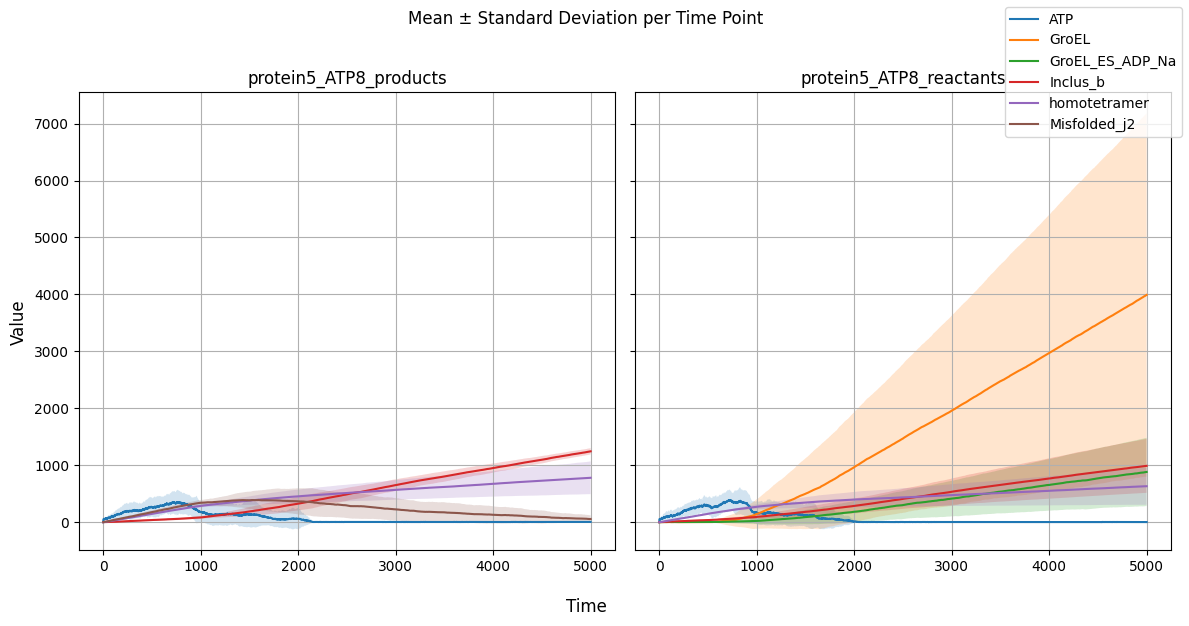

In [4]:
# plot per simulation
cols = ['ATP', 'GroEL', 'GroEL_ES_ADP_Na', 'Inclus_b', 'homotetramer', 'Misfolded_j2']

protein_keys = list(results_mean.keys())
n = len(protein_keys)

plots_per_fig = 2
n_figs = math.ceil(n / plots_per_fig)

width_in, height_in = 12, 6  # tweak if you like

for fig_i in range(n_figs):
    start = fig_i * plots_per_fig
    end   = min(start + plots_per_fig, n)
    keys_chunk = protein_keys[start:end]

    fig, axes = plt.subplots(1, 2, figsize=(width_in, height_in), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax_i, protein_key in enumerate(keys_chunk):
        ax = axes[ax_i]

        mean_per_time = results_mean[protein_key]
        std_per_time  = results_std[protein_key]

        for col in cols:
            mean = mean_per_time[col]
            std  = std_per_time[col]

            ax.plot(mean.index, mean.values, label=col)
            ax.fill_between(
                mean.index,
                mean - std,
                mean + std,
                alpha=0.2
            )

        ax.set_title(protein_key)
        ax.grid(True)

    # turn off unused axes if chunk < 9
    for j in range(len(keys_chunk), plots_per_fig):
        axes[j].axis("off")

    # common labels
    fig.supxlabel("Time")
    fig.supylabel("Value")
    fig.suptitle("Mean ± Standard Deviation per Time Point", y=1.02)

    # legend once, outside the grid
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right")

    plt.tight_layout()
    plt.show()


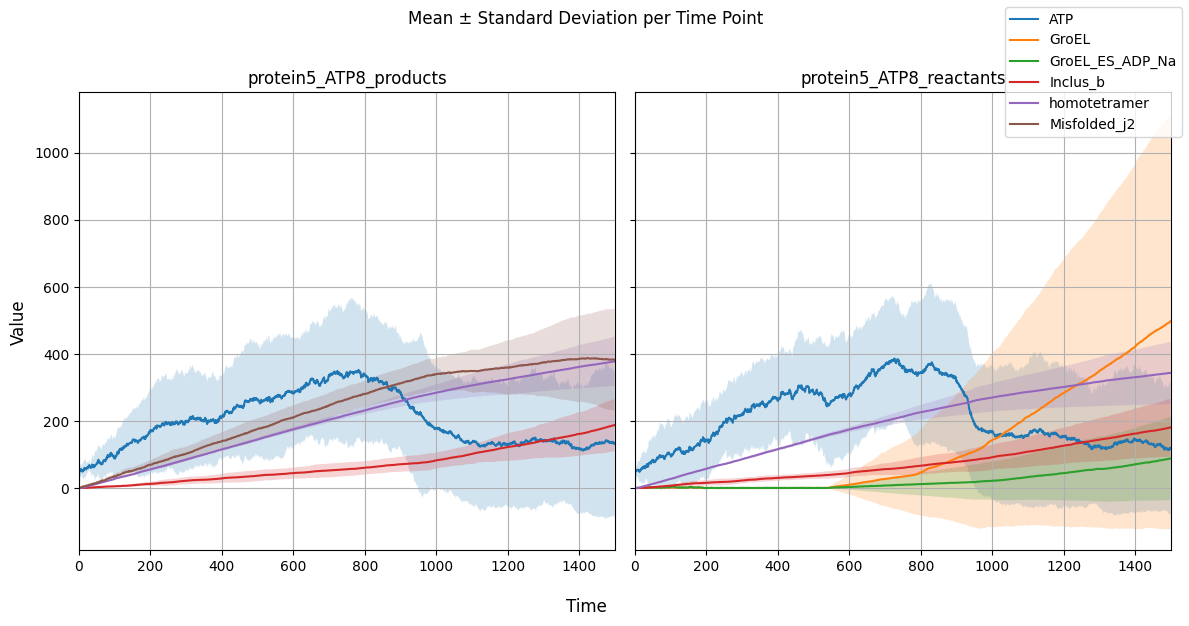

In [ ]:
# plots with reduced time frames
cols = ['ATP', 'GroEL', 'GroEL_ES_ADP_Na', 'Inclus_b', 'homotetramer', 'Misfolded_j2']

protein_keys = list(results_mean.keys())
n = len(protein_keys)

plots_per_fig = 2
n_figs = math.ceil(n / plots_per_fig)

width_in, height_in = 12, 6

for fig_i in range(n_figs):
    start = fig_i * plots_per_fig
    end   = min(start + plots_per_fig, n)
    keys_chunk = protein_keys[start:end]

    fig, axes = plt.subplots(
        1, 2, figsize=(width_in, height_in),
        sharex=True, sharey=True
    )
    axes = axes.flatten()

    for ax_i, protein_key in enumerate(keys_chunk):
        ax = axes[ax_i]

        mean_per_time = results_mean[protein_key]
        std_per_time  = results_std[protein_key]

        for col in cols:
            mean = mean_per_time[col]
            std  = std_per_time[col]

            # only use data where time < 1500
            mask = mean.index < 1500
            x = mean.index[mask]
            y = mean.values[mask]
            y_low = (mean - std)[mask]
            y_high = (mean + std)[mask]

            # plot mean line and std band
            ax.plot(x, y, label=col)
            ax.fill_between(x, y_low, y_high, alpha=0.2)

        ax.set_title(protein_key)
        ax.grid(True)
        ax.set_xlim(0, 1500)  # x-axis only up to 1500

    # turn off unused axes if there are not 2 plots
    for j in range(len(keys_chunk), plots_per_fig):
        axes[j].axis("off")

    # common labels
    fig.supxlabel("Time")
    fig.supylabel("Value")
    fig.suptitle("Mean ± Standard Deviation per Time Point", y=1.02)

    # legend once, outside the grid
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right")

    plt.tight_layout()
    plt.show()


In [6]:
# EXPORT results
results_mean_df = pd.concat(results_mean, names=["experiment", "Time"])
results_std_df = pd.concat(results_std, names=["experiment", "Time"])

results_mean_df.to_parquet("results_mean_reactions.parquet")
results_std_df.to_parquet("results_std_reactions.parquet")